### **Session 6 · Notebook 1 — Transfer learning I: ResNet50 as a feature extractor**
Session 6 deck, *Working with CNNs (II): transfer learning*. Run in Colab with a GPU (Runtime → Change runtime type → T4 GPU).

**The idea.** ResNet50 was trained on 1.28 M ImageNet photos (1,000 classes, ~120 of them dog breeds and
several cats). Its convolutional base already knows edges, textures, fur, eyes, ears. We **reuse the base
frozen** and train only a new, tiny head (GAP → Dropout → Dense(1)).

Compare with Session 5: from scratch, our best network reached **96.3 %** after 29 minutes and 53 epochs.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow info messages
import json, time, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
print("Keras", keras.__version__, "| TensorFlow", tf.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU"))
keras.utils.set_random_seed(1337)
os.makedirs("results", exist_ok=True)

I0000 00:00:1792077379.342522   29790 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792077381.125221   29790 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.12.3 | TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
IMG_SIZE = (224, 224)  # pretrained ImageNet models were trained at 224 x 224 (or larger)
BATCH = 64                 # same batch size as Session 5 => exactly the same test images
SEED = 1337                # same seed as Session 5 => same train / val / test split
WEIGHTS = "imagenet"       # pretrained weights (None = random weights, only for testing the code)
QUICK = False              # True: ~20% of the training batches (fast trial run)

In [3]:
# --- 1. Download the Kaggle Cats and Dogs data (Microsoft PetImages) -----------------------------
URL = ("https://download.microsoft.com/download/3/E/1/"
       "3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip")
DATA_DIR = "PetImages"
if not os.path.isdir(DATA_DIR):
    print("Downloading (about 790 MB)...")
    urllib.request.urlretrieve(URL, "catsdogs.zip")
    with zipfile.ZipFile("catsdogs.zip") as z:
        z.extractall(".")
    os.remove("catsdogs.zip")

# --- 2. Clean once: delete unreadable files, re-encode the rest as standard RGB JPEGs ------------
# (removes the "Corrupt JPEG data: ... extraneous bytes" warnings seen in Session 5)
from PIL import Image
MARK = os.path.join(DATA_DIR, ".cleaned")
if not os.path.exists(MARK):
    removed = []
    for folder in ("Cat", "Dog"):
        path = os.path.join(DATA_DIR, folder)
        for fname in os.listdir(path):
            fpath = os.path.join(path, fname)
            try:
                with Image.open(fpath) as im:
                    im = im.convert("RGB"); im.load()
                im.save(fpath, "JPEG", quality=95)
            except Exception:
                os.remove(fpath); removed.append(f"{folder}/{fname}")
    open(MARK, "w").write("\n".join(removed))
    print(len(removed), "files removed")
for folder in ("Cat", "Dog"):
    print(folder, len(os.listdir(os.path.join(DATA_DIR, folder))), "images")

Cat 12499 images
Dog 12499 images


In [4]:
# --- 3. Train / validation / test: 70 / 15 / 15, identical to Session 5 --------------------------
train_ds, rest_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.3, subset="both", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="binary")
class_names = train_ds.class_names
n_rest = int(rest_ds.cardinality())
val_ds, test_ds = rest_ds.take(n_rest // 2), rest_ds.skip(n_rest // 2)
if QUICK:
    train_ds = train_ds.take(int(train_ds.cardinality()) // 5)
N_TRAIN, N_VAL, N_TEST = (int(d.cardinality()) for d in (train_ds, val_ds, test_ds))
AUTOTUNE = tf.data.AUTOTUNE
train_ds, val_ds, test_ds = (d.prefetch(AUTOTUNE) for d in (train_ds, val_ds, test_ds))
print(class_names, "| batches of", BATCH, ": train", N_TRAIN, "val", N_VAL, "test", N_TEST)

Found 24998 files belonging to 2 classes.
Using 17499 files for training.
Using 7499 files for validation.
['Cat', 'Dog'] | batches of 64 : train 274 val 59 test 59


In [5]:
def make_augmentation():          # a new instance for each model (models may use different image sizes)
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
    ], name="augmentation")

In [6]:
# --- The transfer-learning model: augmentation -> preprocessing -> pretrained base -> new head ----
# The base and the head are separate sub-models: we can freeze the base, and Grad-CAM (Notebook 5)
# can read the base output (the last convolutional feature maps).
BASES = {
    "ResNet50": (keras.applications.ResNet50, keras.applications.resnet.preprocess_input),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
    "EfficientNetB3": (keras.applications.EfficientNetB3, keras.applications.efficientnet.preprocess_input),
    "EfficientNetV2S": (keras.applications.EfficientNetV2S, keras.applications.efficientnet_v2.preprocess_input),
}

def build_transfer(base_name, dropout=0.2, img_size=None, weights="default"):
    img_size = img_size or IMG_SIZE
    make_base, preprocess = BASES[base_name]
    base = make_base(include_top=False, weights=WEIGHTS if weights == "default" else weights,
                     input_shape=tuple(img_size) + (3,))
    base.trainable = False                                   # phase 1: frozen
    head = keras.Sequential([
        keras.Input(base.output.shape[1:]),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid", dtype="float32"),   # float32 output (mixed precision)
    ], name="head")
    inputs = keras.Input(shape=tuple(img_size) + (3,))       # raw pixels 0..255
    x = make_augmentation()(inputs)
    x = layers.Lambda(preprocess, name="preprocess")(x)       # the base's OWN normalisation
    x = base(x, training=False)                               # BN always in inference mode
    outputs = head(x)
    return keras.Model(inputs, outputs, name=f"tl_{base_name}"), base

def count(model):
    tr = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    return model.count_params(), tr

def unfreeze(base, n_last=None):
    """Make the last n_last layers of the base trainable (None = all). BatchNorm stays frozen."""
    base.trainable = True
    layers_ = base.layers if n_last is None else base.layers[-n_last:]
    for l in base.layers:
        l.trainable = l in layers_ and not isinstance(l, layers.BatchNormalization)

In [7]:
# --- Evaluation helpers (as in Session 5) ---------------------------------------------------------
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

def evaluate(model, ds, name, tta=False):
    y_true, p, imgs = [], [], []
    for x, y in ds:
        pr = model.predict(x, verbose=0)[:, 0]
        if tta:                                    # test-time augmentation: average with the mirror image
            pr = 0.5 * (pr + model.predict(tf.image.flip_left_right(x), verbose=0)[:, 0])
        p.append(pr); y_true.append(y.numpy()[:, 0])
        if len(imgs) < 6: imgs.append(x.numpy().astype("uint8"))
    y_true, p = np.concatenate(y_true).astype(int), np.concatenate(p)
    y_pred = (p >= 0.5).astype(int)
    acc = float((y_true == y_pred).mean()); cm = confusion_matrix(y_true, y_pred)
    print(f"{name}: test accuracy = {acc:.4f} on {len(y_true)} images | errors: {int((y_true != y_pred).sum())}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Purples", colorbar=False)
    ax.set_title(f"{name} -- test accuracy {acc:.2%}")
    fig.tight_layout(); fig.savefig(f"results/{name}_cm.png", dpi=600); plt.show()
    return dict(acc=acc, cm=cm.tolist(), y_true=y_true, p=p, imgs=np.concatenate(imgs))

def plot_history(hs, name, labels):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    start = 0
    for h, lab in zip(hs, labels):
        ep = range(start + 1, start + len(h["loss"]) + 1)
        for k, a in [("accuracy", ax[0]), ("loss", ax[1])]:
            a.plot(ep, h[k], "--", label=f"train ({lab})"); a.plot(ep, h["val_" + k], label=f"val ({lab})")
        start += len(h["loss"])
    for k, a in [("accuracy", ax[0]), ("loss", ax[1])]:
        a.set_xlabel("epoch"); a.set_title(k); a.grid(alpha=.3); a.legend(fontsize=7)
    if len(hs) > 1:
        for a in ax: a.axvline(len(hs[0]["loss"]) + 0.5, color="grey", ls=":")
    fig.tight_layout(); fig.savefig(f"results/{name}_curves.png", dpi=600); plt.show()

def show_errors(res, name, n=10):
    k = len(res["imgs"]); wrong = np.where((res["p"][:k] >= 0.5) != res["y_true"][:k])[0][:n]
    if len(wrong) == 0: print("no errors in the first batches"); return
    fig, ax = plt.subplots(1, len(wrong), figsize=(2 * len(wrong), 2.4))
    for a, i in zip(np.atleast_1d(ax), wrong):
        a.imshow(res["imgs"][i]); a.axis("off")
        a.set_title(f"true {class_names[res['y_true'][i]]}\nP(dog)={res['p'][i]:.2f}", fontsize=8)
    fig.tight_layout(); fig.savefig(f"results/{name}_errors.png", dpi=600); plt.show()

def save_summary(name, model, hs, res, secs, extra=None):
    total, trainable = count(model)
    s = dict(name=name, params=total, test_acc=res["acc"], cm=res["cm"], minutes=round(secs / 60, 1),
             epochs=sum(len(h["loss"]) for h in hs),
             best_val_acc=float(max(max(h["val_accuracy"]) for h in hs)), **(extra or {}))
    json.dump(dict(summary=s, histories=hs), open(f"results/{name}.json", "w"))
    print(json.dumps(s, indent=1))
    print(f"\n>>> for the slides: test accuracy = {100*res['acc']:.2f}% | errors = "
          f"{int(round((1-res['acc'])*len(res['y_true'])))} | training time = {secs/60:.1f} min | "
          f"weights = {total:,}")

def fit(model, epochs, lr, name, callbacks=None, wd=None, label_smoothing=0.0, schedule=False):
    steps = epochs * N_TRAIN
    rate = keras.optimizers.schedules.CosineDecay(lr, steps) if schedule else lr
    opt = keras.optimizers.AdamW(rate, weight_decay=wd) if wd else keras.optimizers.Adam(rate)
    model.compile(optimizer=opt, loss=keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing),
                  metrics=["accuracy"])
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks or [])
    secs = time.time() - t0
    print(f"{name}: {secs/60:.1f} min, {secs/max(1,len(h.history['loss'])):.0f} s/epoch")
    return {k: [float(v) for v in vs] for k, vs in h.history.items()}, secs

## 1. Build the model and freeze the base
Only the head's 2,049 weights are trainable. **Preprocessing**: ResNet50 expects its own input
normalisation (`resnet.preprocess_input`: RGB→BGR and ImageNet mean subtraction), not `Rescaling(1/255)`.

In [8]:
model, base = build_transfer("ResNet50")
total, trainable = count(model)
print(f"weights: {total:,}  trainable: {trainable:,}  frozen: {total - trainable:,}")
model.summary()

weights: 23,589,761  trainable: 2,049  frozen: 23,587,712


Model: "tl_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Lambda)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Sequential)               │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 2. Train the head (5 epochs, Adam 1e-3)

In [9]:
EPOCHS = 5
h, secs = fit(model, EPOCHS, 1e-3, "nb1")

Epoch 1/5
274/274 ━━━━━━━━━━━━━━━━━━━━ 37s 113ms/step - accuracy: 0.9557 - loss: 0.1159 - val_accuracy: 0.9868 - val_loss: 0.0408
Epoch 2/5
274/274 ━━━━━━━━━━━━━━━━━━━━ 31s 115ms/step - accuracy: 0.9749 - loss: 0.0660 - val_accuracy: 0.9873 - val_loss: 0.0368
Epoch 3/5
274/274 ━━━━━━━━━━━━━━━━━━━━ 37s 134ms/step - accuracy: 0.9772 - loss: 0.0598 - val_accuracy: 0.9870 - val_loss: 0.0357
Epoch 4/5
274/274 ━━━━━━━━━━━━━━━━━━━━ 36s 133ms/step - accuracy: 0.9784 - loss: 0.0567 - val_accuracy: 0.9868 - val_loss: 0.0360
Epoch 5/5
274/274 ━━━━━━━━━━━━━━━━━━━━ 36s 133ms/step - accuracy: 0.9805 - loss: 0.0522 - val_accuracy: 0.9883 - val_loss: 0.0352
nb1: 3.0 min, 36 s/epoch


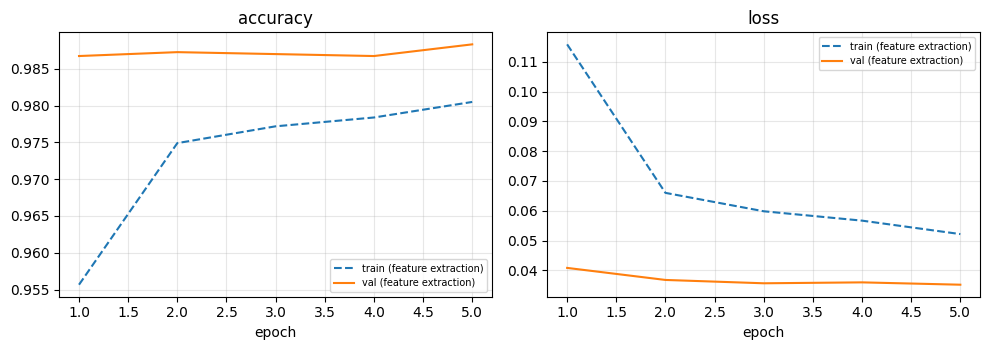

nb1: test accuracy = 0.9906 on 3723 images | errors: 35
              precision    recall  f1-score   support

         Cat      0.993     0.988     0.991      1876
         Dog      0.988     0.993     0.991      1847

    accuracy                          0.991      3723
   macro avg      0.991     0.991     0.991      3723
weighted avg      0.991     0.991     0.991      3723



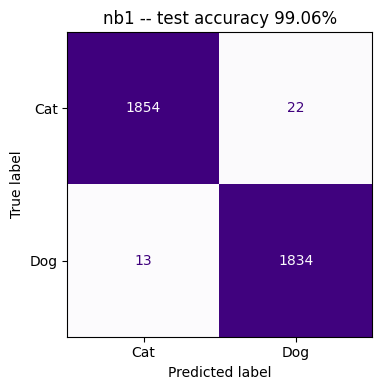

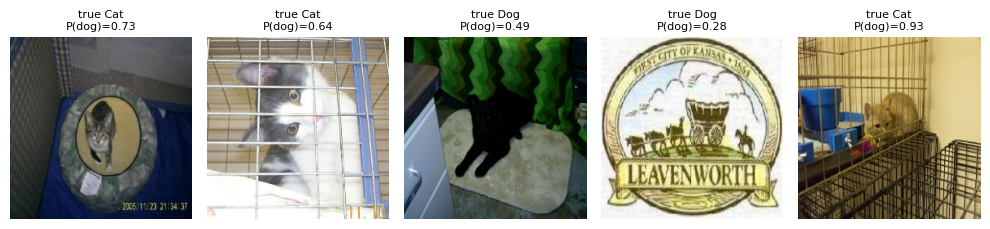

{
 "name": "nb1",
 "params": 23589761,
 "test_acc": 0.9905989793177545,
 "cm": [
  [
   1854,
   22
  ],
  [
   13,
   1834
  ]
 ],
 "minutes": 3.0,
 "epochs": 5,
 "best_val_acc": 0.9883474707603455,
 "trainable": 2049,
 "base": "ResNet50",
 "img": 224
}

>>> for the slides: test accuracy = 99.06% | errors = 35 | training time = 3.0 min | weights = 23,589,761


In [10]:
plot_history([h], "nb1", ["feature extraction"])
res = evaluate(model, test_ds, "nb1")
show_errors(res, "nb1")
save_summary("nb1", model, [h], res, secs, extra=dict(trainable=trainable, base="ResNet50", img=IMG_SIZE[0]))
model.save_weights("results/nb1.weights.h5")

## Questions
1. How many epochs does it take to beat the Session 5 network? How many minutes?
2. Why is training so fast, if ResNet50 has 23.6 M weights?
3. Validation accuracy is higher than training accuracy in the first epochs. Why? (Hint: augmentation and dropout.)